In [4]:
!pip -q install --upgrade kaggle

import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter token: ")

Enter token: ··········


In [5]:
import os

print("Token loaded:", bool(os.environ.get("KAGGLE_API_TOKEN")))

Token loaded: True


In [6]:
!kaggle datasets files abdallahalidev/plantvillage-dataset --page-size=5


Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7g2Zg-rxtzKTQGV4VOpJhy9K4tyfjtM4D4LfF1RR-Kw8ngvJevYaJLHNXH6RpDYlSHLCF42EWx3x0kEnGvl5FnvjGZcafLjKSfeA_Ao1ysY3rSeSSaq48MGJsWDCZsgwZ_Xq2t6lSHvG3k0qfwJShV_1LVu3bJKJ-o9PfJZTXQkab-WOxVwFQ574OZsxc7urVKzxNsAs17s
name                                                                                 size  creationDate                
----------------------------------------------------------------------------------  -----  --------------------------  
color/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG   9616  2019-11-18 02:24:53.874000  
color/Apple___Apple_scab/01a66316-0e98-4d3b-a56f-d78752cd043f___FREC_Scab 3003.JPG  10108  2019-11-18 02:24:53.866000  
color/Apple___Apple_scab/01f3deaa-6143-4b6c-9c22-620a46d8be04___FREC_Scab 3112.JPG  12005  2019-11-18 02:24:53.828000  
color/Apple___Apple_scab/0208f4eb-45a4-4399-904e-989ac2c6257c___FREC_Scab 3037.JPG  19474  2019-11-18 02:24:53.795000  
color/Apple___Apple_scab/023123cb

In [7]:
!mkdir -p /content/data/PlantVillage

!kaggle datasets download \
    -d abdallahalidev/plantvillage-dataset \
    -p /content/data/PlantVillage \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:23<00:00, 94.2MB/s]



In [8]:
!mkdir -p /content/data/Tomato_Leaves

!kaggle datasets download \
    -d ashishmotwani/tomato \
    -p /content/data/Tomato_Leaves \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/ashishmotwani/tomato
License(s): copyright-authors
100% 1.37G/1.37G [00:17<00:00, 83.3MB/s]



In [9]:
from pathlib import Path

base_path = Path("/content/data")

for dataset_name in ["PlantVillage", "Tomato_Leaves"]:
    dataset_path = base_path / dataset_name

    print(f"\n{'=' * 40}")
    print(dataset_name)
    print(f"{'=' * 40}")

    if not dataset_path.exists():
        print("Dataset folder not found!")
        continue

    for item in sorted(dataset_path.iterdir()):
        if item.is_dir():
            image_count = sum(
                1 for file in item.rglob("*")
                if file.is_file()
                and file.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
                }
            )
            print(f"Folder: {item.name} | Images: {image_count}")
        else:
            print(f"File: {item.name}")


PlantVillage
Folder: plantvillage dataset | Images: 162916

Tomato_Leaves
Folder: train | Images: 25851
Folder: valid | Images: 6683


In [10]:
from pathlib import Path

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

def count_images(folder):
    return sum(
        1 for file in folder.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    )

# 1. Inspect PlantVillage
pv = Path(
    "/content/data/PlantVillage/plantvillage dataset"
)

print("=== PlantVillage ===")

for folder in sorted(pv.iterdir()):
    if folder.is_dir():
        print(f"\n{folder.name}: {count_images(folder)} images")

        # Show class counts for the color images
        if folder.name.lower() == "color":
            for class_folder in sorted(folder.iterdir()):
                if class_folder.is_dir():
                    print(
                        f"  {class_folder.name}: "
                        f"{count_images(class_folder)} images"
                    )

# 2. Inspect Tomato Leaves
tomato = Path("/content/data/Tomato_Leaves")

print("\n=== Tomato Leaves ===")

for split in ["train", "valid"]:
    split_folder = tomato / split
    print(f"\n{split}:")

    for class_folder in sorted(split_folder.iterdir()):
        if class_folder.is_dir():
            print(
                f"  {class_folder.name}: "
                f"{count_images(class_folder)} images"
            )

=== PlantVillage ===

color: 54305 images
  Apple___Apple_scab: 630 images
  Apple___Black_rot: 621 images
  Apple___Cedar_apple_rust: 275 images
  Apple___healthy: 1645 images
  Blueberry___healthy: 1502 images
  Cherry_(including_sour)___Powdery_mildew: 1052 images
  Cherry_(including_sour)___healthy: 854 images
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513 images
  Corn_(maize)___Common_rust_: 1192 images
  Corn_(maize)___Northern_Leaf_Blight: 985 images
  Corn_(maize)___healthy: 1162 images
  Grape___Black_rot: 1180 images
  Grape___Esca_(Black_Measles): 1383 images
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
  Grape___healthy: 423 images
  Orange___Haunglongbing_(Citrus_greening): 5507 images
  Peach___Bacterial_spot: 2297 images
  Peach___healthy: 360 images
  Pepper,_bell___Bacterial_spot: 997 images
  Pepper,_bell___healthy: 1478 images
  Potato___Early_blight: 1000 images
  Potato___Late_blight: 1000 images
  Potato___healthy: 152 images
  Raspberry__

In [11]:
from pathlib import Path
from PIL import Image
import pandas as pd
import hashlib

base = Path("/content/data")

pv_color = (
    base / "PlantVillage"
    / "plantvillage dataset" / "color"
)

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = []

# Collect tomato images from PlantVillage (color only)
for folder in sorted(pv_color.iterdir()):
    if folder.is_dir() and folder.name.startswith("Tomato___"):
        label = folder.name.removeprefix("Tomato___")

        for path in folder.rglob("*"):
            if path.is_file() and path.suffix.lower() in extensions:
                images.append({
                    "path": str(path),
                    "source": "PlantVillage",
                    "original_split": "unsplit",
                    "original_class": label,
                    "class_label": label.lower().replace(" ", "_")
                })

# Collect images from Tomato Leaves
for split in ["train", "valid"]:
    split_path = base / "Tomato_Leaves" / split

    for folder in sorted(split_path.iterdir()):
        if folder.is_dir():
            label = folder.name

            for path in folder.rglob("*"):
                if path.is_file() and path.suffix.lower() in extensions:
                    images.append({
                        "path": str(path),
                        "source": "Tomato_Leaves",
                        "original_split": split,
                        "original_class": label,
                        "class_label": label.lower().replace(" ", "_")
                    })

print("Images to inspect:", len(images))

# Inspect image readability and calculate exact file hashes
seen_hashes = {}
results = []

for i, item in enumerate(images, start=1):
    row = item.copy()
    row.update({
        "status": "ok",
        "sha256": None,
        "exact_duplicate": False,
        "duplicate_of": None,
        "label_conflict": False,
        "error": None
    })

    try:
        with Image.open(row["path"]) as img:
            img.verify()

        digest = hashlib.sha256()

        with open(row["path"], "rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                digest.update(chunk)

        file_hash = digest.hexdigest()
        row["sha256"] = file_hash

        if file_hash in seen_hashes:
            first_path, first_label = seen_hashes[file_hash]
            row["exact_duplicate"] = True
            row["duplicate_of"] = first_path
            row["label_conflict"] = (
                row["class_label"] != first_label
            )
        else:
            seen_hashes[file_hash] = (
                row["path"], row["class_label"]
            )

    except Exception as error:
        row["status"] = "corrupt"
        row["error"] = str(error)[:200]

    results.append(row)

    if i % 1000 == 0:
        print(f"Checked {i:,} / {len(images):,}")

# Save the audit report without deleting any files
report = pd.DataFrame(results)
report_path = base / "tomato_image_audit.csv"
report.to_csv(report_path, index=False)

print("\n--- Audit summary ---")
print("Total images:", len(report))
print("Unreadable images:", (report["status"] == "corrupt").sum())
print("Exact duplicate copies:", report["exact_duplicate"].sum())
print(
    "Duplicates with different labels:",
    report["label_conflict"].sum()
)
print("Report saved to:", report_path)

Images to inspect: 50694
Checked 1,000 / 50,694
Checked 2,000 / 50,694
Checked 3,000 / 50,694
Checked 4,000 / 50,694
Checked 5,000 / 50,694
Checked 6,000 / 50,694
Checked 7,000 / 50,694
Checked 8,000 / 50,694
Checked 9,000 / 50,694
Checked 10,000 / 50,694
Checked 11,000 / 50,694
Checked 12,000 / 50,694
Checked 13,000 / 50,694
Checked 14,000 / 50,694
Checked 15,000 / 50,694
Checked 16,000 / 50,694
Checked 17,000 / 50,694
Checked 18,000 / 50,694
Checked 19,000 / 50,694
Checked 20,000 / 50,694
Checked 21,000 / 50,694
Checked 22,000 / 50,694
Checked 23,000 / 50,694
Checked 24,000 / 50,694
Checked 25,000 / 50,694
Checked 26,000 / 50,694
Checked 27,000 / 50,694
Checked 28,000 / 50,694
Checked 29,000 / 50,694
Checked 30,000 / 50,694
Checked 31,000 / 50,694
Checked 32,000 / 50,694
Checked 33,000 / 50,694
Checked 34,000 / 50,694
Checked 35,000 / 50,694
Checked 36,000 / 50,694
Checked 37,000 / 50,694
Checked 38,000 / 50,694
Checked 39,000 / 50,694
Checked 40,000 / 50,694
Checked 41,000 / 50,694


In [12]:
# Images that were readable and have a calculated hash
valid = report[report["sha256"].notna()].copy()

# All images whose exact hash appears more than once
duplicate_groups = valid.groupby("sha256").filter(
    lambda group: len(group) > 1
)

print("=== Duplicate analysis ===")
print("Unique duplicated image hashes:",
      duplicate_groups["sha256"].nunique())

print("\nOccurrences in each source and split")
print(
    duplicate_groups.groupby(
        ["source", "original_split"]
    ).size().to_string()
)

# Exact duplicates that occur in both datasets
cross_source = valid.groupby("sha256").filter(
    lambda group: group["source"].nunique() > 1
)

print("\nDuplicate entries across both datasets:",
      len(cross_source))
print("Unique hashes across both datasets:",
      cross_source["sha256"].nunique())

# Exact duplicates appearing in both train and valid
tomato_only = valid[valid["source"] == "Tomato_Leaves"]

train_hashes = set(
    tomato_only.loc[
        tomato_only["original_split"] == "train", "sha256"
    ]
)
valid_hashes = set(
    tomato_only.loc[
        tomato_only["original_split"] == "valid", "sha256"
    ]
)

train_valid_overlap = train_hashes & valid_hashes

print("\nTomato Leaves exact duplicates shared by train and valid:",
      len(train_valid_overlap))

# Show the three label-conflict cases and all rows sharing those hashes
conflict_hashes = report.loc[
    report["label_conflict"], "sha256"
].dropna().unique()

print("\n=== Label conflicts: inspect before deciding ===")

if len(conflict_hashes):
    print(
        report[report["sha256"].isin(conflict_hashes)][
            ["source", "original_split", "original_class", "path"]
        ].to_string(index=False)
    )
else:
    print("No conflicting-label cases found.")

=== Duplicate analysis ===
Unique duplicated image hashes: 15453

Occurrences in each source and split
source         original_split
PlantVillage   unsplit           15253
Tomato_Leaves  train             13156
               valid              3379

Duplicate entries across both datasets: 31360
Unique hashes across both datasets: 15239

Tomato Leaves exact duplicates shared by train and valid: 392

=== Label conflicts: inspect before deciding ===
       source original_split     original_class                                                                                 path
Tomato_Leaves          train     Bacterial_spot               /content/data/Tomato_Leaves/train/Bacterial_spot/Septoria Leafspot.jpg
Tomato_Leaves          train     Bacterial_spot /content/data/Tomato_Leaves/train/Bacterial_spot/Septoria_Leaf_Spot_of_Tomato186.jpg
Tomato_Leaves          train       Early_blight             /content/data/Tomato_Leaves/train/Early_blight/lateblightTom_lesion3.jpg
Tomato_Leaves   


Conflict group 1
Source: Tomato_Leaves
Split: train
Class: Early_blight
File: /content/data/Tomato_Leaves/train/Early_blight/lateblightTom_lesion3.jpg


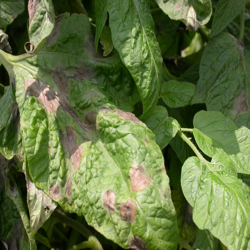

Source: Tomato_Leaves
Split: train
Class: Late_blight
File: /content/data/Tomato_Leaves/train/Late_blight/LB_ (255).jpg


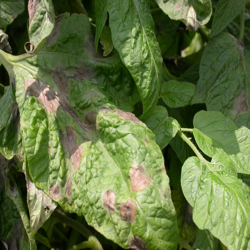


Conflict group 2
Source: Tomato_Leaves
Split: train
Class: Bacterial_spot
File: /content/data/Tomato_Leaves/train/Bacterial_spot/Septoria Leafspot.jpg


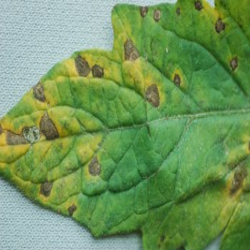

Source: Tomato_Leaves
Split: train
Class: Septoria_leaf_spot
File: /content/data/Tomato_Leaves/train/Septoria_leaf_spot/Septoria Leafspot.jpg


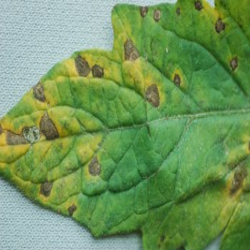


Conflict group 3
Source: Tomato_Leaves
Split: train
Class: Bacterial_spot
File: /content/data/Tomato_Leaves/train/Bacterial_spot/Septoria_Leaf_Spot_of_Tomato186.jpg


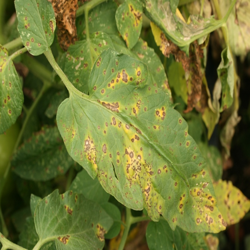

Source: Tomato_Leaves
Split: valid
Class: Septoria_leaf_spot
File: /content/data/Tomato_Leaves/valid/Septoria_leaf_spot/SS_ (925).jpg


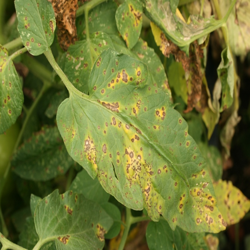

In [13]:
from IPython.display import display
from PIL import Image

conflict_hashes = (
    report.loc[report["label_conflict"], "sha256"]
    .dropna()
    .unique()
)

for number, image_hash in enumerate(conflict_hashes, start=1):
    group = report[report["sha256"] == image_hash]

    print(f"\n{'=' * 50}")
    print(f"Conflict group {number}")

    for _, row in group.iterrows():
        print("Source:", row["source"])
        print("Split:", row["original_split"])
        print("Class:", row["original_class"])
        print("File:", row["path"])

        try:
            with Image.open(row["path"]) as img:
                display(img.convert("RGB").resize((250, 250)))
        except Exception as error:
            print("Could not display:", error)

In [14]:
# Hashes of images with conflicting labels
conflict_hashes = set(
    report.loc[report["label_conflict"], "sha256"].dropna()
)

# Exclude unreadable images and all copies of conflicting images
clean_candidates = report[
    (report["status"] == "ok")
    & (~report["sha256"].isin(conflict_hashes))
].copy()

# Keep exactly one path for each unique image
unique_images = clean_candidates.drop_duplicates(
    subset="sha256",
    keep="first"
).copy()

# Save a manifest (file list), not copies of the images
manifest_path = "/content/data/tomato_unique_manifest.csv"

unique_images[
    [
        "path",
        "source",
        "original_split",
        "original_class",
        "class_label",
        "sha256"
    ]
].to_csv(manifest_path, index=False)

print("Original image records:", len(report))
print("Conflicting image groups excluded:", len(conflict_hashes))
print("Unique images retained:", len(unique_images))
print("\nImages per class:")
print(unique_images["class_label"].value_counts().sort_index())
print("\nManifest saved to:", manifest_path)

Original image records: 50694
Conflicting image groups excluded: 3
Unique images retained: 34356

Images per class:
class_label
bacterial_spot                          3556
early_blight                            2745
healthy                                 3706
late_blight                             3733
leaf_mold                               3094
powdery_mildew                          1256
septoria_leaf_spot                      3621
spider_mites_two-spotted_spider_mite    2182
target_spot                             2284
tomato_mosaic_virus                     2736
tomato_yellow_leaf_curl_virus           5443
Name: count, dtype: int64

Manifest saved to: /content/data/tomato_unique_manifest.csv


In [15]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Use the unique, readable images after excluding label conflicts
data = unique_images[
    [
        "path",
        "source",
        "original_split",
        "original_class",
        "class_label",
        "sha256",
    ]
].copy()

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=42,
    stratify=data["class_label"],
)

# Split the temporary part equally into validation and test
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["class_label"],
)

train_df = train_df.assign(split="train")
valid_df = valid_df.assign(split="valid")
test_df = test_df.assign(split="test")

# Combine the three sets into one manifest
split_df = pd.concat(
    [train_df, valid_df, test_df],
    ignore_index=True,
)

split_df = split_df.sample(
    frac=1,
    random_state=42,
).reset_index(drop=True)

# Verify that the same exact image hash is not in multiple splits
hash_sets = {
    name: set(split_df.loc[split_df["split"] == name, "sha256"])
    for name in ["train", "valid", "test"]
}

assert hash_sets["train"].isdisjoint(hash_sets["valid"])
assert hash_sets["train"].isdisjoint(hash_sets["test"])
assert hash_sets["valid"].isdisjoint(hash_sets["test"])

# Save the split CSV
output_path = "/content/data/tomato_dataset_split.csv"
split_df.to_csv(output_path, index=False)

print("Split sizes:")
print(split_df["split"].value_counts())

print("\nClass distribution:")
print(pd.crosstab(split_df["class_label"], split_df["split"]))

print("\nExact duplicate leakage check: PASSED")
print("CSV saved to:", output_path)

Split sizes:
split
train    24049
test      5154
valid     5153
Name: count, dtype: int64

Class distribution:
split                                 test  train  valid
class_label                                             
bacterial_spot                         534   2489    533
early_blight                           412   1922    411
healthy                                556   2594    556
late_blight                            560   2613    560
leaf_mold                              464   2166    464
powdery_mildew                         188    879    189
septoria_leaf_spot                     543   2535    543
spider_mites_two-spotted_spider_mite   327   1527    328
target_spot                            342   1599    343
tomato_mosaic_virus                    411   1915    410
tomato_yellow_leaf_curl_virus          817   3810    816

Exact duplicate leakage check: PASSED
CSV saved to: /content/data/tomato_dataset_split.csv


In [16]:
from pathlib import Path
from google.colab import files

# Make paths relative to the dataset root
split_df["relative_path"] = split_df["path"].map(
    lambda p: Path(p).relative_to("/content/data").as_posix()
)

# Select columns needed for the team's dataset manifest
portable_df = split_df[
    [
        "relative_path",
        "source",
        "original_split",
        "original_class",
        "class_label",
        "sha256",
        "split",
    ]
].copy()

output_path = "/content/data/tomato_dataset_split.csv"
portable_df.to_csv(output_path, index=False)

# Verify all referenced images still exist in this session
missing = sum(
    not (Path("/content/data") / p).is_file()
    for p in portable_df["relative_path"]
)

print("Total rows:", len(portable_df))
print("Missing image files:", missing)
print("\nSplit counts:")
print(portable_df["split"].value_counts())
print("\nSaved:", output_path)

# Download the CSV to your computer
files.download(output_path)

Total rows: 34356
Missing image files: 0

Split counts:
split
train    24049
test      5154
valid     5153
Name: count, dtype: int64

Saved: /content/data/tomato_dataset_split.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
split_df["relative_path"] = split_df["relative_path"].str.replace(
    r"^/content/data/?", "", regex=True
)

split_df.to_csv("/content/data/tomato_dataset_split.csv", index=False)

from google.colab import files
files.download("/content/data/tomato_dataset_split.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
import os

print("هل التقسيمة موجودة؟", "split_df" in globals())

if "split_df" in globals():
    print("عدد الصور:", len(split_df))
    print("أعمدة الملف:", split_df.columns.tolist())

    for p in split_df["relative_path"].head(5):
        path = os.path.join("/content/data", str(p))
        print(os.path.exists(path), p)
else:
    print("التقسيمة مش موجودة في الجلسة الحالية.")

هل التقسيمة موجودة؟ True
عدد الصور: 34356
أعمدة الملف: ['path', 'source', 'original_split', 'original_class', 'class_label', 'sha256', 'split', 'relative_path']
True PlantVillage/plantvillage dataset/color/Tomato___Bacterial_spot/9da4708d-8ea4-406f-8850-7fd97efbd129___UF.GRC_BS_Lab Leaf 8969.JPG
True PlantVillage/plantvillage dataset/color/Tomato___Tomato_Yellow_Leaf_Curl_Virus/e4b674d9-661c-4e26-96b2-311501d928ec___UF.GRC_YLCV_Lab 02250.JPG
True PlantVillage/plantvillage dataset/color/Tomato___Tomato_Yellow_Leaf_Curl_Virus/9ca05607-17fe-4710-b8d7-abf0b9451f0a___UF.GRC_YLCV_Lab 02181.JPG
True Tomato_Leaves/train/Septoria_leaf_spot/2010-jul-5-jul-9-03_jpg.rf.42ac337c1a6a0cecb3e10aca9b3ac411.jpg
True PlantVillage/plantvillage dataset/color/Tomato___Bacterial_spot/a0fb8315-0051-4631-bcc7-2ef60e9d63c8___GCREC_Bact.Sp 6114.JPG


In [19]:
split_df = split_df.drop(columns=["path"], errors="ignore")

split_df.to_csv(
    "/content/data/tomato_dataset_split.csv",
    index=False
)

from google.colab import files
files.download("/content/data/tomato_dataset_split.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>